# 3. Going further: bandits and the "peeking" problem

Notebooks 1 and 2 ran a **classic A/B test**: split the traffic 50/50, wait, then
decide. This notebook explores two ideas that come up whenever a team runs lots of
experiments — and separates the parts that are real from the parts that are hype.

- **Part A/B — Multi-armed bandits & Thompson sampling:** instead of a fixed 50/50
  split, learn *while you run* and send more traffic to whatever is winning.
- **Part C — "Can Bayesian let me stop early?"** The short answer is *not by
  itself* — and we prove it with a simulation, then show the honest fix.

Plain-English throughout; the maths is in the cells if you want it.

## Part A — Explore vs exploit (the "multi-armed bandit")

**The analogy.** Picture a row of slot machines ("one-armed bandits") that each
pay out at different, unknown rates. Pulling a lever is a tiny experiment. You
face a dilemma every pull:

- **Exploit:** keep pulling the machine that's paid off best so far.
- **Explore:** try the others, because one of them might be better.

Spend too long exploring and you waste pulls on losers; exploit too early and you
might get stuck on a mediocre machine. A **bandit algorithm** is just a rule for
balancing the two. In our case the "machines" are the two versions of the app,
and a "pull" is one user seeing a version.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

%matplotlib inline

# Illustrative "true" conversion rates, matching the rates we recovered in the study.
P_A, P_B = 0.396, 0.424
BEST = max(P_A, P_B)
N = 20000  # number of "rounds" = users
rng = np.random.default_rng(7)
print(f"True conversion — A: {P_A:.1%},  B: {P_B:.1%}.  B is better, but only just.")

True conversion — A: 39.6%,  B: 42.4%.  B is better, but only just.


### Baseline: the fixed 50/50 test

This is what we did in the study. It's the honest, clean approach when you want a
trustworthy *measurement*. But notice: half of everyone is sent to the worse
version the whole time.

In [2]:
def simulate_fixed(p_arms, n, rng):
    arms = rng.integers(0, 2, n)  # random 50/50 assignment
    probs = np.where(arms == 0, p_arms[0], p_arms[1])
    rewards = (rng.random(n) < probs).astype(int)  # did they convert?
    regret = np.cumsum(BEST - probs)  # foregone conversions vs always-B
    return arms, np.cumsum(rewards), regret


fixed_arms, fixed_conv, fixed_regret = simulate_fixed((P_A, P_B), N, rng)
print(f"Fixed test total conversions: {fixed_conv[-1]:,}")

Fixed test total conversions: 8,175


## Part B — Thompson sampling

**Thompson sampling** is a beautifully simple rule:

1. Keep a belief (a Beta distribution) about each version's true conversion rate.
2. For the next user, **draw one random sample** from each belief.
3. Send the user to whichever version drew the higher number.
4. See if they converted, and update that version's belief.

Versions that look good get picked more (exploit), but every version still has a
chance of drawing high (explore) — and that chance shrinks automatically as the
evidence piles up. Best of all, it uses the *same* Beta-Binomial maths from
notebook 2.

In [3]:
def thompson(p_arms, n, rng):
    alpha = np.ones(2)
    beta = np.ones(2)  # one Beta belief per version
    arms = np.empty(n, int)
    rewards = np.empty(n, int)
    for t in range(n):
        sample = rng.beta(alpha, beta)  # draw from each belief
        k = int(np.argmax(sample))  # pick the more promising version
        r = int(rng.random() < p_arms[k])
        alpha[k] += r
        beta[k] += 1 - r  # update that belief
        arms[t] = k
        rewards[t] = r
    probs = np.where(arms == 0, p_arms[0], p_arms[1])
    regret = np.cumsum(BEST - probs)
    return arms, np.cumsum(rewards), regret


ts_arms, ts_conv, ts_regret = thompson((P_A, P_B), N, rng)
print(f"Thompson total conversions:   {ts_conv[-1]:,}")
print(f"Final share of traffic sent to B: {(ts_arms[-1000:] == 1).mean():.0%}")

Thompson total conversions:   8,452
Final share of traffic sent to B: 99%


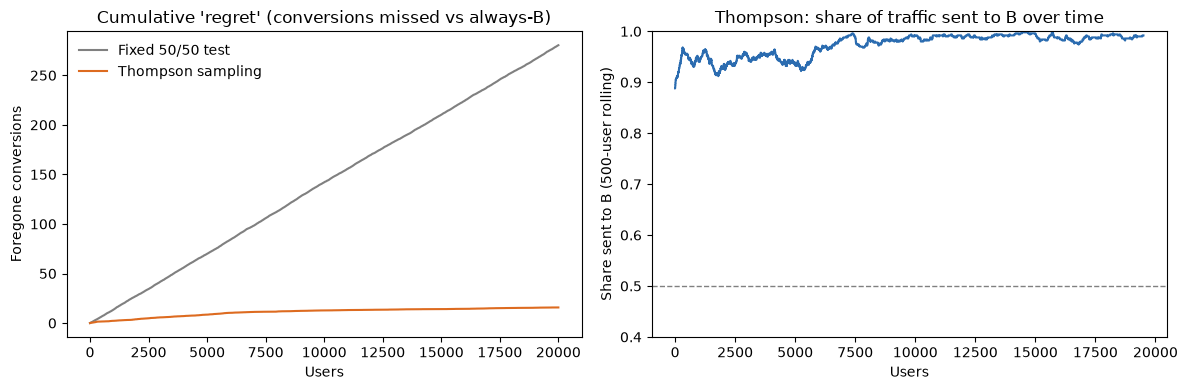

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(fixed_regret, color="grey", label="Fixed 50/50 test")
axes[0].plot(ts_regret, color="#dd6b20", label="Thompson sampling")
axes[0].set_title("Cumulative 'regret' (conversions missed vs always-B)")
axes[0].set_xlabel("Users")
axes[0].set_ylabel("Foregone conversions")
axes[0].legend(frameon=False)

window = 500
share_b = np.convolve((ts_arms == 1).astype(float), np.ones(window) / window, "valid")
axes[1].plot(share_b, color="#2b6cb0")
axes[1].axhline(0.5, color="grey", ls="--", lw=1)
axes[1].set_title("Thompson: share of traffic sent to B over time")
axes[1].set_xlabel("Users")
axes[1].set_ylabel("Share sent to B (500-user rolling)")
axes[1].set_ylim(0.4, 1.0)
plt.tight_layout()
plt.show()

**What this tells us.** Because the two versions are *close* (only ~3 points apart),
the extra conversions from a bandit are modest — a couple of hundred over 20,000
users. The traffic share for B drifts up but never to 100%, because it keeps a
little exploration going forever (which is correct).

**The trade-off in one line:** a bandit maximises *reward during the test*; a
fixed A/B test maximises *the quality of the measurement*. You run a bandit when
you mainly want to make money as you learn, and an A/B test when you need a clean,
publishable answer. For a regulated financial product — where you'd want a clear,
defensible result before changing people's savings — the fixed test is usually the
right call. **That's why we didn't use a bandit in the main study.**

## Part C — The "peeking" problem

Here's where a lot of blog posts over-promise. The claim usually goes:

> *"With Bayesian stats you can peek at the results and stop the moment you're
> confident — no penalty."*

**That is not true.** If you keep checking and stop the instant the result looks
good, you will find "winners" that aren't real — whether you use p-values *or*
Bayesian probabilities. Let's prove it.

**The setup.** Imagine A and B are actually **identical** (both convert at 40%).
There is no real difference. We now run 2,000 separate experiments, checking every
500 users, and count how often the test wrongly declares a winner.

In [5]:
def two_prop_p(yA, nA, yB, nB):
    pA, pB = yA / nA, yB / nB
    p = (yA + yB) / (nA + nB)
    se = np.sqrt(p * (1 - p) * (1 / nA + 1 / nB))
    if se == 0:
        return 1.0
    return 2 * (1 - stats.norm.cdf(abs((pB - pA) / se)))


def post_P_B_gt_A(yA, nA, yB, nB):
    # Beta(1,1) posteriors, normal approximation to P(B > A)
    mA = (1 + yA) / (2 + nA)
    vA = (1 + yA) * (1 + nA - yA) / ((2 + nA) ** 2 * (3 + nA))
    mB = (1 + yB) / (2 + nB)
    vB = (1 + yB) * (1 + nB - yB) / ((2 + nB) ** 2 * (3 + nB))
    return stats.norm.cdf((mB - mA) / np.sqrt(vA + vB))


def false_positive_rate(rule, thr, n_exp=2000, n_users=20000, batch=500, p=0.40, seed=1):
    rng = np.random.default_rng(seed)
    K = n_users // batch
    wrong = 0
    for _ in range(n_exp):
        yA = nA = yB = nB = 0
        for k in range(1, K + 1):
            h = batch // 2
            yA += rng.binomial(h, p)
            nA += h
            yB += rng.binomial(h, p)
            nB += h
            stop = False
            if rule == "bayes_peek":
                pba = post_P_B_gt_A(yA, nA, yB, nB)
                stop = pba > thr or pba < 1 - thr
            elif rule == "pval_peek":
                stop = two_prop_p(yA, nA, yB, nB) < thr
            elif rule == "pval_bonferroni":
                stop = two_prop_p(yA, nA, yB, nB) < thr / K  # corrected for K looks
            elif rule == "single_look" and k == K:
                stop = two_prop_p(yA, nA, yB, nB) < thr
            if stop:
                wrong += 1
                break
    return wrong / n_exp


rates = {
    "Bayesian: stop when P(B>A)>95% (repeated looks)": false_positive_rate("bayes_peek", 0.95),
    "Bayesian: stop when P(B>A)>99% (repeated looks)": false_positive_rate("bayes_peek", 0.99),
    "Frequentist: stop when p<0.05 (repeated looks)": false_positive_rate("pval_peek", 0.05),
    "Frequentist: one look at the end (p<0.05)": false_positive_rate("single_look", 0.05),
    "Frequentist: Bonferroni box (p<0.05/40)": false_positive_rate("pval_bonferroni", 0.05),
}
for k, v in rates.items():
    print(f"{v:6.1%}   {k}")

 49.1%   Bayesian: stop when P(B>A)>95% (repeated looks)
 14.5%   Bayesian: stop when P(B>A)>99% (repeated looks)
 29.8%   Frequentist: stop when p<0.05 (repeated looks)
  4.5%   Frequentist: one look at the end (p<0.05)
  1.1%   Frequentist: Bonferroni box (p<0.05/40)


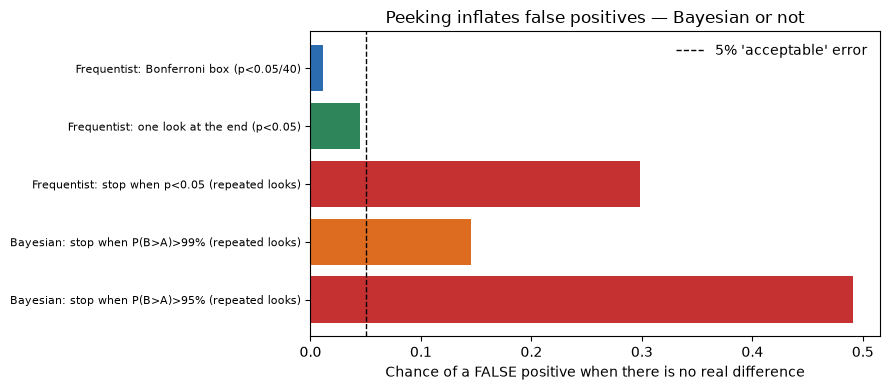

In [6]:
plt.figure(figsize=(9, 4))
names = list(rates)
vals = [rates[k] for k in names]
colors = ["#c53030", "#dd6b20", "#c53030", "#2f855a", "#2b6cb0"]
plt.barh(range(len(names)), vals, color=colors)
plt.axvline(0.05, color="black", ls="--", lw=1, label="5% 'acceptable' error")
plt.yticks(range(len(names)), names, fontsize=8)
plt.xlabel("Chance of a FALSE positive when there is no real difference")
plt.title("Peeking inflates false positives — Bayesian or not")
plt.legend(frameon=False)
plt.tight_layout()
plt.show()

**What this tells us.**

- Repeated peeking with a 95% Bayesian threshold finds a "winner" in a large
  fraction of experiments where **there is no winner at all**. (Same story with
  p < 0.05.)
- Raising the bar to 99% helps, but is still not a clean guarantee.
- A **single, pre-planned look** gives the honest ~5%, and a simple correction
  (here, Bonferroni: require p < 0.05 ÷ number-of-looks) brings repeated peeking
  back under control.

**So what *is* the right answer?** Bayesian analysis gives you a genuinely useful
decision quantity — the **expected loss** (the average cost of picking the wrong
version; we used it in notebook 2). A defensible way to stop early is to
**pre-specify a rule** like *"stop only when expected loss is below a small
threshold"*, ideally combined with a method that is designed for continuous
monitoring (a **sequential** or **always-valid** method). The tools are Bayesian;
the *discipline* of pre-specifying the stopping rule is what protects you — not
the label "Bayesian".

## The takeaway

- **Bandits / Thompson sampling** trade a slightly less clean measurement for more
  reward *during* the test. Great when experimentation is continuous; we chose a
  fixed test because a defensible result mattered more than squeezing out a few
  hundred extra conversions.
- **Peeking** is a real trap, and "it's Bayesian" is not a fix. Pre-specify your
  stopping rule; use expected-loss or sequential methods to do it properly.

This is the kind of nuance worth bringing up in an interview: knowing *why* you'd
use one design over another is the senior-level signal, not just knowing the maths.